In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [2]:
print("Loading MNIST dataset...")
X,y=fetch_openml(
    'mnist_784',
    version=1,
    return_X_y=True,
    as_frame=False
)

X=X.astype('float32')
y=y.astype('int')
print("Dataset loaded successfully!")
print("Total samples:",X.shape[0])
print("Number of features:",X.shape[1])

Loading MNIST dataset...
Dataset loaded successfully!
Total samples: 70000
Number of features: 784


In [3]:
X=X/255.0
X=X[:20000]
y=y[:20000]
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("\nTraining samples:",X_train.shape[0])
print("\nTesting Samples:",X_test.shape[0])


Training samples: 16000

Testing Samples: 4000


In [4]:
activations=['logistic','relu','tanh']
results={}
training_times={}
accuracies={}

In [5]:
for activation in activations:
    print("\n---------------------------")
    print("Training with:",activation)
    print("\n---------------------------")
    
    start_time=time.time()
    
    model=MLPClassifier(
        hidden_layer_sizes=(128,),
        activation=activation,
        solver='adam',
        max_iter=100,
        batch_size=128,
        random_state=42,
        verbose=False
    )
    
    model.fit(X_train,y_train)
    end_time=time.time()
    training_time=end_time-start_time
    y_pred=model.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    results[activation]=model
    training_times[activation]=training_time
    accuracies[activation]=accuracy*100
    print("Training time:{:.2f} seconds".format(training_time))
    print("Number of iterations:",model.n_iter_)
    print("Test accuracy:{:.2f}%".format(accuracy*100))


---------------------------
Training with: logistic

---------------------------
Training time:256.84 seconds
Number of iterations: 99
Test accuracy:95.58%

---------------------------
Training with: relu

---------------------------
Training time:186.10 seconds
Number of iterations: 56
Test accuracy:96.23%

---------------------------
Training with: tanh

---------------------------
Training time:155.34 seconds
Number of iterations: 61
Test accuracy:95.80%


In [6]:
print("\n===================================")
print("ACTIVATION FUNCTION COMPARISON")
print("\n===================================")
print("{:<12} {:<15} {:<15} {:<15}".format(
"Activation","Time(sec)","Iterations","Accuracy(%)"
))
for activation in activations:
    model = results[activation]
    print("{:<12} {:<15.2f} {:<15} {:<15.2f}".format(
    activation,
    training_times[activation],
    model.n_iter_,
    accuracies[activation]
))


ACTIVATION FUNCTION COMPARISON

Activation   Time(sec)       Iterations      Accuracy(%)    
logistic     256.84          99              95.58          
relu         186.10          56              96.23          
tanh         155.34          61              95.80          


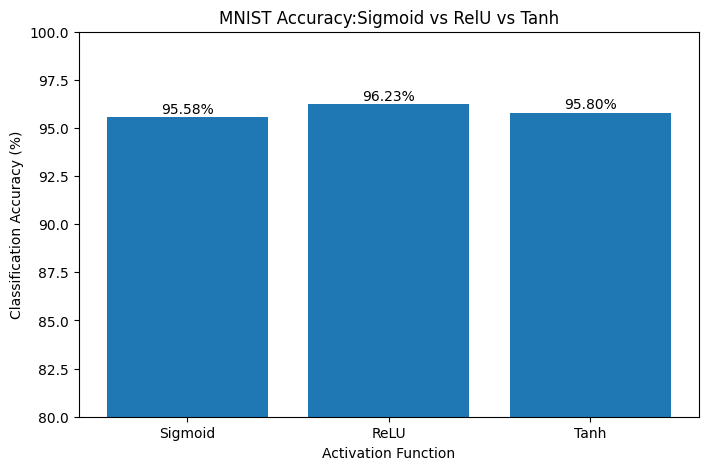

In [7]:
plt.figure(figsize=(8,5))
plt.bar(
    ['Sigmoid','ReLU','Tanh'],
    [
        accuracies['logistic'],
        accuracies['relu'],
        accuracies['tanh']
    ]
)
plt.xlabel("Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Classification Accuracy (%)")
plt.title("MNIST Accuracy:Sigmoid vs RelU vs Tanh")
plt.ylim(80,100)
for i, value in enumerate([
    accuracies['logistic'],
    accuracies['relu'],
    accuracies['tanh']
]):
    plt.text(i,value+0.2,f"{value:.2f}%",
             ha='center')
plt.show()

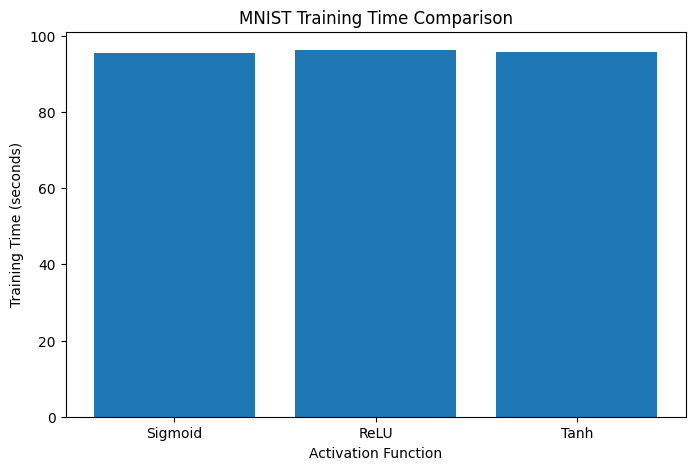

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(
['Sigmoid','ReLU','Tanh'],
[
accuracies['logistic'],
accuracies['relu'],
accuracies['tanh']
]
)

plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")
plt.title("MNIST Training Time Comparison")
plt.show()






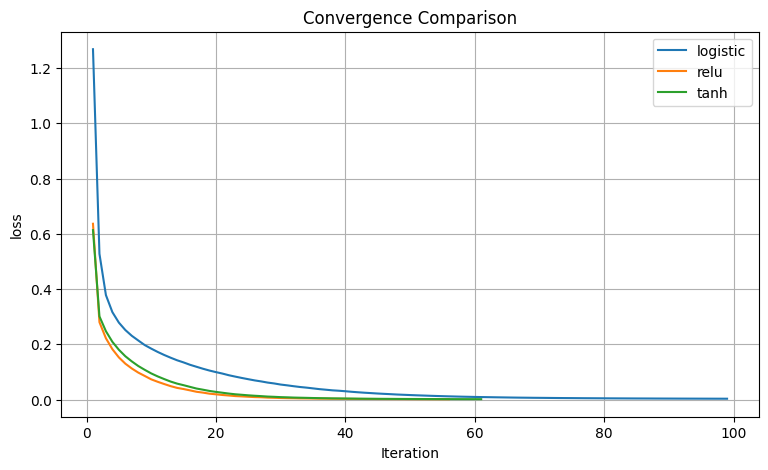

In [9]:
plt.figure(figsize=(9,5))
for activation in activations:
    model = results[activation]
    plt.plot(
    range(1,len(model.loss_curve_)+1),
    model.loss_curve_,
    label=activation
    )
plt.xlabel("Iteration")
plt.ylabel("loss")
plt.title("Convergence Comparison")
plt.legend()
plt.grid(True)
plt.show()